# Inverse design of a 3 × 3 flat-top array with incoherent illumination

We design a phase pupil that turns the light from five extended emitters into nine evenly illuminated squares on a nearby monitor. This is the finite-distance example in Fig. 7 and Supplement S7. Equation (24) is used here and supplies the irradiance used during optimization.



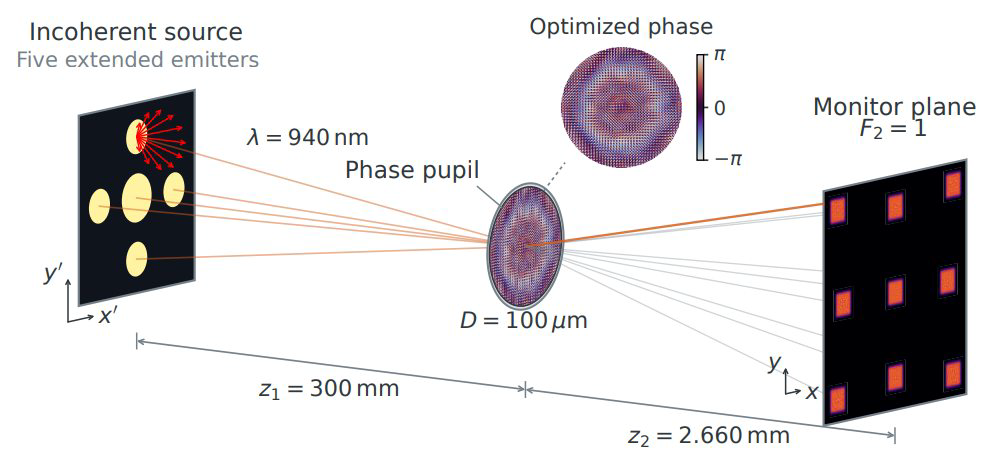

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf
import jax
jax.config.update("jax_enable_x64", True)
from jax.example_libraries import optimizers

import diffractsim
diffractsim.set_backend("JAX")
from diffractsim import (IncoherentLightSimulation, ApertureFromFunction,
                        phase_grating_design, mm, um, nm)
from diffractsim.util.backend_functions import backend as bd
from diffractsim.util.phase_grating import periodic_phase_grating

plt.rcParams["figure.dpi"] = 140

## 1. Design the starting grating

We first design a periodic phase cell that sends equal power into the nine orders $m,n\in\{-1,0,1\}$. `phase_grating_design` searches a $128\times128$ cell, then refines it on a $512\times512$ grid. The larger refinement weight puts more emphasis on balancing the order powers.

The plot shows one period of the phase. We will use this grating to initialize the pupil below.

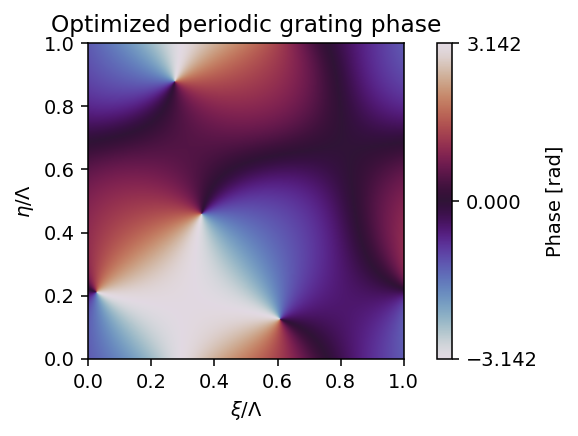

In [2]:
# 1. Design and plot one phase-grating cell.
def target_orders(m, n):
    return (abs(m) <= 1) & (abs(n) <= 1)

phase, search_history = phase_grating_design(target_orders, Nx=128, seed=2,iterations=2000, learning_rate=0.03, weight=0.5)
phase_cell, fine_history = phase_grating_design(target_orders, Nx=512, initial_phase=phase,iterations=1500, learning_rate=0.01, weight=10)

fig, ax = plt.subplots(figsize=(4, 3), layout="constrained")
im = ax.imshow(np.angle(np.exp(1j*np.asarray(phase_cell))), origin="lower", extent=(0, 1, 0, 1), cmap="twilight", vmin=-np.pi, vmax=np.pi)
ax.set(title="Optimized periodic grating phase", xlabel=r"$\xi/\Lambda$", ylabel=r"$\eta/\Lambda$")
fig.colorbar(im, ax=ax, label="Phase [rad]", ticks=[-np.pi, 0, np.pi])
plt.show()

## 2. Define the illumination

Five extended emmiters of equal radiance lie at $z_1=300\,\mathrm{mm}$ from the pupil. Their light adds incoherently. We use $\lambda=940\,\mathrm{nm}$ and pupil radius $a=50\,\mu\mathrm{m}$; the monitor distance is set by $F_2=a^2/(\lambda z_2)=1$, giving $z_2\simeq2.660\,\mathrm{mm}$.


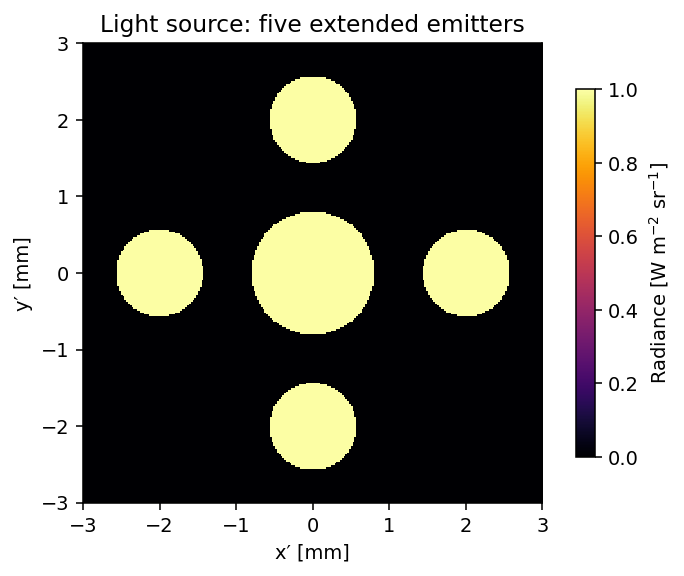

In [3]:
# 2. Define and plot the five extended emitters.
wavelength, radius, period = 940*nm, 50*um, 2.35*um
z1, F2 = 300*mm, 1.0
z2, pixel = radius**2/(wavelength*F2), period/5
N = int(np.ceil(2*radius/pixel))
sim_flattop = IncoherentLightSimulation(wavelength, N*pixel, N*pixel, N, N)

emitter_centres = np.array([[0, 0], [2, 0], [-2, 0], [0, 2], [0, -2]])*mm
emitter_radii = np.array([0.8]+[0.8/np.sqrt(2)]*4)*mm

def flattop_source(x, y):
    """Equal radiance on five disks; their intensities add incoherently."""
    L = bd.zeros_like(x)
    for (cx, cy), r in zip(emitter_centres, emitter_radii):
        L = L + ((x-cx)**2+(y-cy)**2 <= r*r)
    return L

source_limit = (2*mm+emitter_radii[1])/z1
sim_flattop.set_illumination_from_plane(flattop_source, z1, paraxial=False,
    angular_samples=2048, source_subpixels=32,
    source_bounds=(-source_limit, source_limit, -source_limit, source_limit))

fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
sim_flattop.plot_illumination_plane(extent_x=6*mm, extent_y=6*mm,units=mm, ax=ax, title="Light source: five extended emitters")
plt.show()

## 3. Define the target irradiance profile

We place the nine target centers along the grating directions for the central source point, $(\alpha',\beta')=(0,0)$.
The grating equation says:

$$
\alpha_{mn}=\frac{m\lambda}{\Lambda},\qquad
\beta_{mn}=\frac{n\lambda}{\Lambda},\qquad
(x_{mn},y_{mn})=
\frac{z_2(\alpha_{mn},\beta_{mn})}{\sqrt{1-\alpha_{mn}^2-\beta_{mn}^2}},
\quad m,n\in\{-1,0,1\}.
$$

Each target is a $320\,\mu\mathrm{m}$ square with a $20\,\mu\mathrm{m}$ Gaussian edge transition. A $420\times420\,\mu\mathrm{m}$ window around each center includes a dark border, so the loss can penalize light outside the squares.


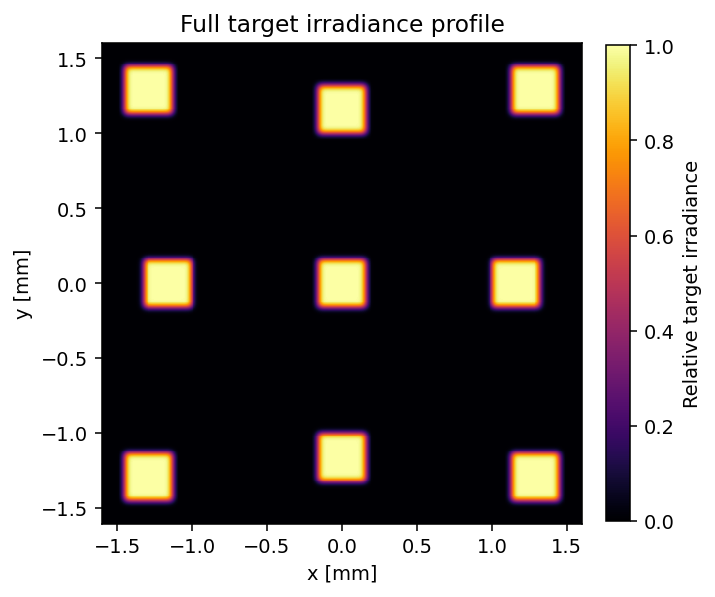

In [4]:
# 3. Define and plot the target irradiance profile.
side, edge, tile_half, screen_step = 320*um, 20*um, 210*um, 5*um

orders = np.array([(m, n) for n in (1, 0, -1) for m in (-1, 0, 1)])
directions = wavelength/period*orders
centres = z2*directions/np.sqrt(1-(directions**2).sum(axis=1))[:, None]
local = np.linspace(-tile_half, tile_half, int(round(2*tile_half/screen_step))+1)
ux, uy = np.meshgrid(local, local)
sim_flattop.x_screen = centres[:, 0, None]+ux.ravel()
sim_flattop.y_screen = centres[:, 1, None]+uy.ravel()

def flattop_profile(x):
    """One square edge, smoothed by a Gaussian of width edge."""
    return 0.5*(erf((side/2-x)/(np.sqrt(2)*edge))+erf((side/2+x)/(np.sqrt(2)*edge)))

profile = flattop_profile(local)
target = bd.asarray(np.outer(profile, profile))
interior, collection = target > 0.95, target >= 0.5

# Preview all nine target squares at their actual monitor positions.
target_axis = np.linspace(-1.6*mm, 1.6*mm, 513)
tx, ty = np.meshgrid(target_axis, target_axis)
target_monitor = sum(flattop_profile(tx-cx)*flattop_profile(ty-cy) for cx, cy in centres)
fig, ax = plt.subplots(figsize=(5, 4.5), layout="constrained")
im = ax.pcolormesh(target_axis/mm, target_axis/mm, target_monitor,
    shading="auto", cmap="inferno", vmin=0, vmax=1)
ax.set(title="Full target irradiance profile", xlabel="x [mm]", ylabel="y [mm]", aspect="equal")
fig.colorbar(im, ax=ax, shrink=0.8, label="Relative target irradiance")
plt.show()


## 4. Build the initial phase

We sample the grating designed in step 1 on a $5\times5$ grid, giving five physical pixels per period, and repeat this pattern across the circular pupil. Let $\phi_{\mathrm g}(\xi,\eta)$ denote this repeated phase.

To spread the initial diffraction orders, we add a diverging quadratic phase:

$$
\phi_0(\xi,\eta)
=
\phi_{\mathrm g}(\xi,\eta)
+
2.8\pi\,\frac{\xi^2+\eta^2}{a^2},
\qquad \xi^2+\eta^2\leq a^2.
$$

Here $a$ is the pupil radius. The added phase increases smoothly from zero at the center to $2.8\pi$ at the rim. This gives the optimizer a starting pattern of broadened spots. During optimization, every illuminated pupil pixel can change independently.

Pupil: 213×213 pixels | z₂: 2.6596 mm | targets: 9 × 85² samples


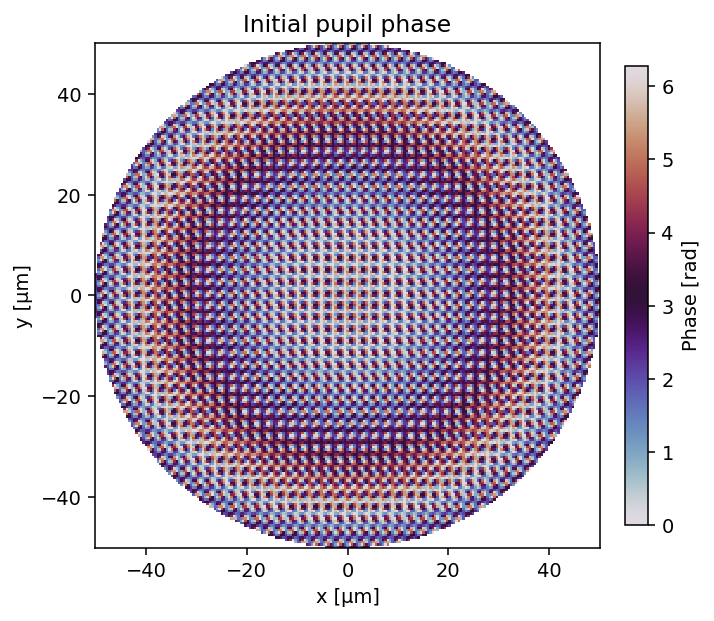

In [5]:
# 4. Build and plot the initial phase.
pupil_mask = sim_flattop.xx**2+sim_flattop.yy**2 <= radius**2

# Sample the grating designed above at five physical pixels per period.
seed_axis = bd.arange(5)*period/5
flattop_seed = bd.angle(periodic_phase_grating(phase_cell, seed_axis, seed_axis, period))
index = bd.rint(sim_flattop.x/pixel).astype(int) % 5
phase_start = flattop_seed[index[:, None], index[None, :]]
# Add the diverging phase used to spread the initial orders.
phase_start += 2.8*bd.pi*(sim_flattop.xx**2+sim_flattop.yy**2)/radius**2
print(f"Pupil: {N}×{N} pixels | z₂: {z2/mm:.4f} mm | targets: 9 × {len(local)}² samples")

fig, ax = plt.subplots(figsize=(5, 4.5), layout="constrained")
sim_flattop.plot_aperture(pupil_mask*bd.exp(1j*phase_start), phase=True,
    units=um, ax=ax, title="Initial pupil phase")
plt.show()


## 5. Define the loss and optimize the phase

Let $\mathcal A$ be the union of the nine windows, $I=\{T>0.95\}$ their combined interiors, and $C=\{T\geq0.5\}$ the collection region. We use one mean, $\overline E_I=\langle E\rangle_I$, for all nine squares. This keeps their brightness on the same scale.

Following Supplement S7.1, the loss is

$$
\mathcal L=
\left\langle\left(E/\overline E_I-T\right)^2\right\rangle_{\mathcal A}
+0.05(1-\eta_{\mathrm{sq}}),
\qquad
\eta_{\mathrm{sq}}=\frac{1}{P_0}\int_C E\,\mathrm dA.
$$

The first term matches the flat interiors, smooth edges and dark surroundings. The second encourages power collection relative to the incident pupil power $P_0$. The forward model uses `model="ASM", sampling="angular"` within Eq. (24). JAX differentiates the loss with respect to the pupil phase, and Adam updates it. We gradually reduce the step size and retain the best phase evaluated during the run.

   0: loss = 0.137039
 200: loss = 0.020195
 400: loss = 0.019722
 600: loss = 0.019575
 800: loss = 0.019478
1000: loss = 0.019399
1200: loss = 0.019350
1400: loss = 0.019326
1600: loss = 0.019313
1800: loss = 0.019304


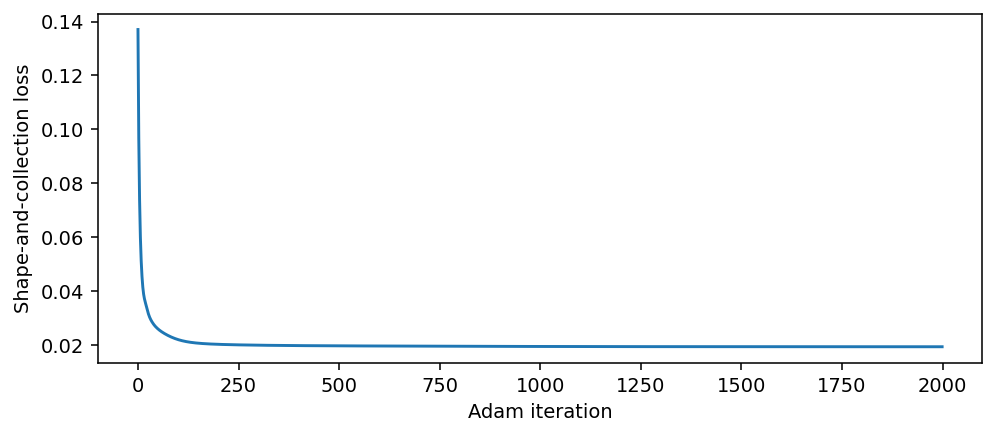

In [6]:
# 5. Define the forward model and loss, then optimize the phase.
iterations, learning_rate = 2000, 0.05
collection_weight = 0.05
incident_power = sim_flattop.get_incident_irradiance()*bd.sum(pupil_mask)*pixel**2

def flattop_irradiance(aperture):
    def model(F, z):
        F = F.add(aperture)
        # x_screen/y_screen specify the nine detector windows.
        return F.zoom_propagate(z, [local[0], local[-1]], [local[0], local[-1]],
            Nx_mon=len(local), Ny_mon=len(local), model="ASM", sampling="angular")
    return sim_flattop.get_irradiance(model, z2)[2].reshape(9, len(local), len(local))

def flattop_loss(phase):
    aperture = ApertureFromFunction(lambda x, y, wl: pupil_mask*bd.exp(1j*phase))
    E = flattop_irradiance(aperture)
    mean = bd.mean(E[:, interior])
    shape_error = bd.mean((E/mean-target)**2)
    efficiency = bd.sum(E*collection)*screen_step**2/incident_power
    return shape_error+collection_weight*(1-efficiency)

def flattop_schedule(i):
    return learning_rate*(0.1+0.9*0.5*(1+bd.cos(bd.pi*i/iterations)))

initialize, update, parameters = optimizers.adam(flattop_schedule)
value_and_gradient = jax.jit(jax.value_and_grad(flattop_loss))
update = jax.jit(update)
state, history, best_loss = initialize(phase_start), [], np.inf
for i in range(iterations):
    phase = parameters(state)
    loss, gradient = value_and_gradient(phase)
    history.append(float(loss))
    if float(loss) < best_loss:
        best_loss, phase_flattop = float(loss), phase
    state = update(i, gradient, state)
    if i % 200 == 0:
        print(f"{i:4d}: loss = {float(loss):.6f}")

fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.plot(history)
ax.set(xlabel="Adam iteration", ylabel="Shape-and-collection loss")
plt.show()

## 6. Inspect the optimized phase

The source and aperture stay fixed while the optimizer changes $\phi(\xi,\eta)$. The resulting pupil is

$$
\mathscr P(\xi,\eta)=\mathbf 1_{\xi^2+\eta^2\leq a^2}\,e^{i\phi(\xi,\eta)}.
$$

We plot only the optimized phase here. Displaying it modulo $2\pi$ leaves the transmitted field unchanged.

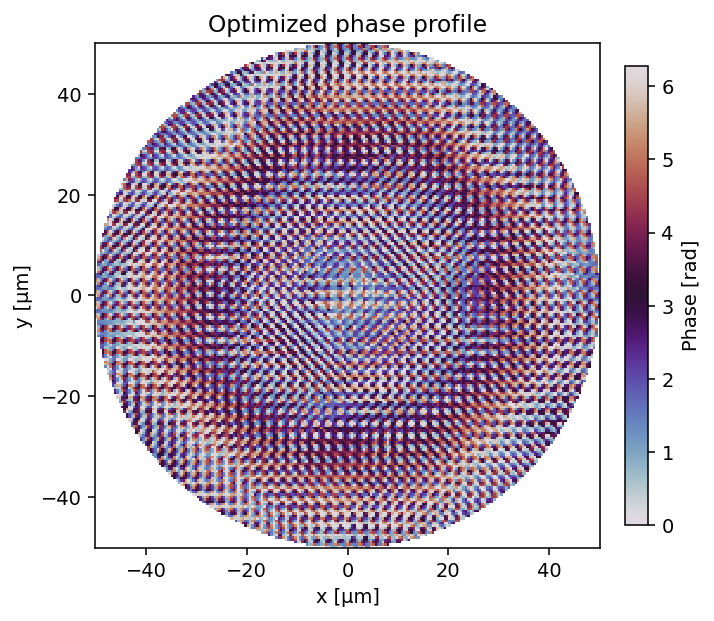

In [7]:
# 6. Inspect the optimized phase profile.
final_flattop_pupil = pupil_mask*bd.exp(1j*phase_flattop)
aperture_flattop = ApertureFromFunction(lambda x, y, wl: final_flattop_pupil)
fig, ax = plt.subplots(figsize=(5, 4.5), layout="constrained")
sim_flattop.plot_aperture(final_flattop_pupil, phase=True,
    units=um, ax=ax, title="Optimized phase profile")
plt.show()

## 7. View the whole monitor

The nine optimization windows show the target regions in detail. We now evaluate the full monitor to see where they sit and how much light falls between them. For this overview, each physical phase pixel is sampled $5\times5$ times without changing its transmission. The next step uses finer angular sampling for the reported metrics.

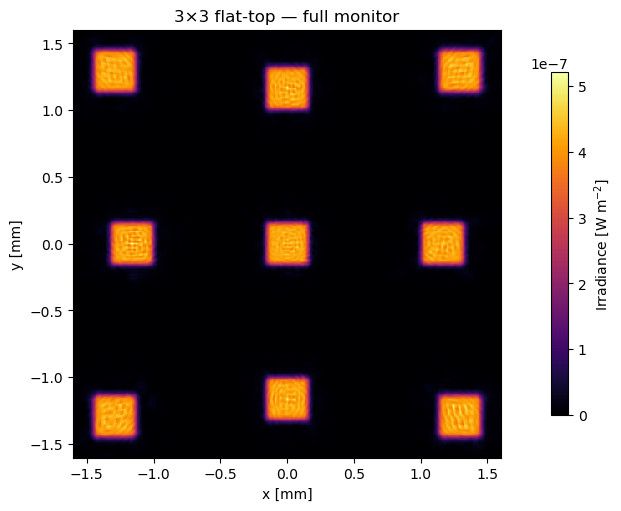

<Axes: title={'center': '3×3 flat-top — full monitor'}, xlabel='x [mm]', ylabel='y [mm]'>

In [8]:
# 7. Full-monitor irradiance, including the space between the nine targets.
# Resolve each physical phase pixel with 5×5 samples for this overview.
sim_monitor = IncoherentLightSimulation(wavelength, N*pixel, N*pixel, 5*N, 5*N)
sim_monitor.set_illumination_from_plane(flattop_source, z1, paraxial=False, angular_samples=1024, source_subpixels=16)
pupil_monitor = bd.repeat(bd.repeat(final_flattop_pupil, 5, axis=0), 5, axis=1)
aperture_monitor = ApertureFromFunction(lambda x, y, wl: pupil_monitor)

def full_monitor_model(F, z):
    F = F.add(aperture_monitor)
    return F.zoom_propagate(z, [-1.6*mm, 1.6*mm], [-1.6*mm, 1.6*mm], Nx_mon=513, Ny_mon=513, model="ASM", sampling="angular")

x_, y_, E_monitor = sim_monitor.get_irradiance(full_monitor_model, z2)
sim_monitor.plot_irradiance(E_monitor, units=mm, cmap="inferno", figsize=(7, 5), text="3×3 flat-top — full monitor")

## 8. Compare the nine squares with the target

We refine the angular convolution grid and evaluate the optimized pupil again. All panels use the same interior mean and color scale, so brightness differences between squares remain visible. The cyan contour marks $T=0.5$, and each title reports that square's collected fraction of incident power.

As in Supplement S7.1, we report the relative target-shape error and interior nonuniformity:

$$
\epsilon_{\mathrm{shape}}=
\frac{\|E/\overline E_I-T\|_{L^2(\mathcal A)}}{\|T\|_{L^2(\mathcal A)}},
\qquad
U=\frac{\operatorname{std}_I(E)}{\overline E_I}.
$$

The shape error includes the edges and dark borders; $U$ measures variation across all nine interiors. The final line plot compares horizontal profiles through an axial, a side and a diagonal square with the target.

Collection: 63.73% | Shape error: 4.89% | Interior nonuniformity: 4.49%


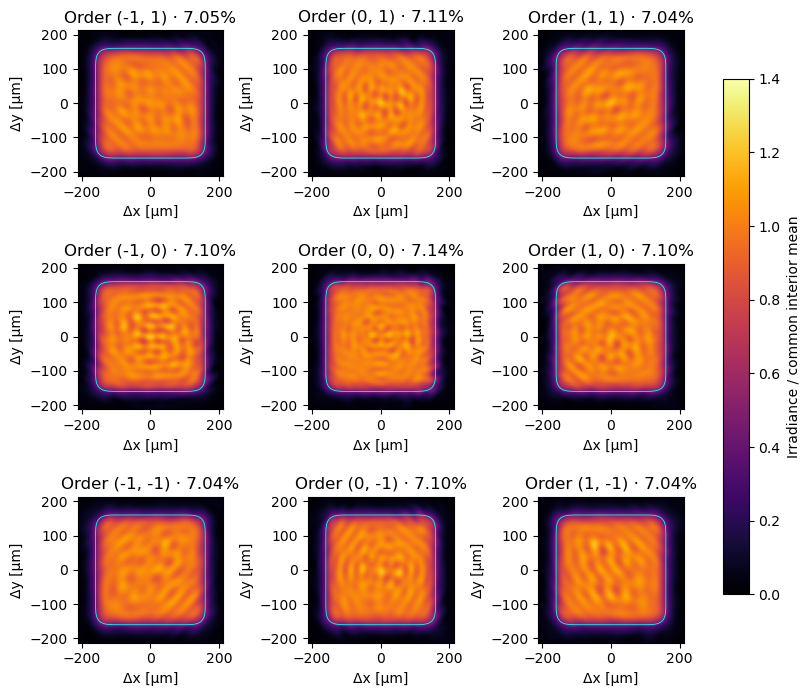

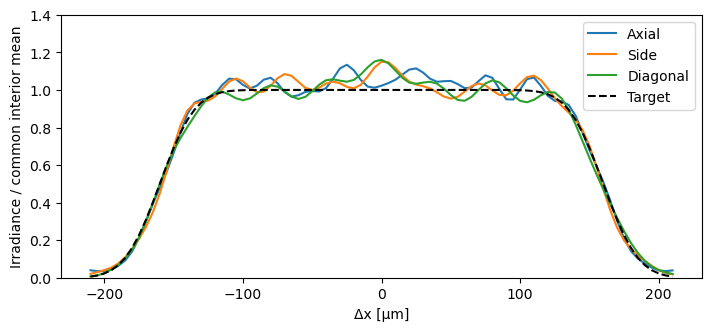

In [9]:
# 8. Finite-monitor irradiance: refine the angular convolution grid, then plot.
sim_flattop.angular_samples, sim_flattop.source_subpixels = 4096, 16
E_flattop = flattop_irradiance(aperture_flattop)
level = bd.mean(E_flattop[:, interior])
powers = bd.sum(E_flattop*collection, axis=(1, 2))*screen_step**2/incident_power
shape_error = bd.sqrt(bd.mean((E_flattop/level-target)**2)/bd.mean(target**2))
nonuniformity = bd.std(E_flattop[:, interior])/level
print(f"Collection: {100*float(powers.sum()):.2f}% | "
      f"Shape error: {100*float(shape_error):.2f}% | "
      f"Interior nonuniformity: {100*float(nonuniformity):.2f}%")

images = np.asarray(E_flattop/level)
extent = [(local[0]-screen_step/2)/um, (local[-1]+screen_step/2)/um]*2
fig, axes = plt.subplots(3, 3, figsize=(8, 7), layout="constrained")
for j, ax in enumerate(axes.flat):
    im = ax.imshow(images[j], origin="lower", extent=extent, cmap="inferno", vmin=0, vmax=1.4)
    ax.contour(local/um, local/um, np.asarray(target), levels=[0.5], colors="cyan", linewidths=0.6)
    ax.set(title=f"Order {tuple(map(int, orders[j]))} · {100*float(powers[j]):.2f}%",
           xlabel="Δx [µm]", ylabel="Δy [µm]")
fig.colorbar(im, ax=axes, shrink=0.8, label="Irradiance / common interior mean")
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.2), layout="constrained")
for j, label in [(4, "Axial"), (5, "Side"), (2, "Diagonal")]:
    ax.plot(local/um, images[j, len(local)//2], label=label)
ax.plot(local/um, np.asarray(target)[len(local)//2], "k--", label="Target")
ax.set(xlabel="Δx [µm]", ylabel="Irradiance / common interior mean", ylim=(0, 1.4))
ax.legend()
plt.show()

# Paper results verification

## 9. Reproduce Fig. 7(b–g)

We now design two pupils from the same starting phase: one with the far-field model, Eq. (22), and one with the finite-distance model, Eq. (24). We also add the prescribed paraxial focus to the Eq. (22) pupil. All three final designs are evaluated with the full RS propagator.


In [12]:
# The appended section has its own names and simulation settings.
from pathlib import Path
import sys
import hashlib
import json
sys.path.insert(0, str(Path("vendor").resolve()))

import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import diffractsim
diffractsim.set_backend("JAX")
from diffractsim import phase_grating_design, um
from diffractsim.util.phase_grating import periodic_phase_grating
from flattop_fig7 import FlatTopDesign

REOPTIMIZE = False
RECHECK_RS = False
REBUILD_START = False
fig7_iterations, fig7_learning_rate = 2000, 0.05
fig7 = FlatTopDesign(screen_step=5*um, angular_step=4/2048)
fig7_folder = Path("fig7_results") / fig7.signature
fig7_folder.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 140
print(f"{fig7.n} × {fig7.n} phase pixels; z₂ = {fig7.z2/1000:.4f} mm; "
      f"{len(fig7.source_mass)} source samples; nine {len(fig7.local)} × {len(fig7.local)} tiles.")

213 × 213 phase pixels; z₂ = 2.6596 mm; 120 source samples; nine 85 × 85 tiles.


### Use the same starting pupil

The geometry follows Supplement S7: $\lambda=940\,\mathrm{nm}$, $a=50\,\mu\mathrm m$, $z_1=300\,\mathrm{mm}$, and $z_2=a^2/\lambda$. Five equal-radiance disks supply 120 quadrature samples: three radial and eight azimuthal samples per disk. Their weights include $c'^4\,\mathrm dA'/z_1^2$ and sum to unit incident irradiance at the pupil centre.

We use the same grating design as the earlier cells, sample five phase pixels per period, and add $2.8\pi(\xi^2+\eta^2)/a^2$. Each illuminated $0.47\,\mu\mathrm m$ square pixel then varies independently. The circular mask selects pixels by their centres. All lengths in the companion module are in micrometres, as in diffractsim.

In [13]:
# Load the reproducible start, or rebuild the same grating used above.
fig7_start_file = Path("fig7_results/initial_phase.npz")
if fig7_start_file.exists() and not REBUILD_START:
    with np.load(fig7_start_file) as data:
        fig7_start = jnp.asarray(data["phase"])
else:
    def fig7_orders(m, n):
        return (abs(m) <= 1) & (abs(n) <= 1)

    fig7_coarse, _ = phase_grating_design(fig7_orders, Nx=128, seed=2,
        iterations=2000, learning_rate=0.03, weight=0.5)
    fig7_fine, _ = phase_grating_design(fig7_orders, Nx=512, initial_phase=fig7_coarse,
        iterations=1500, learning_rate=0.01, weight=10)
    fig7_cell = jnp.angle(periodic_phase_grating(fig7_fine,
        jnp.arange(5)/5, jnp.arange(5)/5, period=1))
    fig7_index = np.rint(fig7.axis/fig7.pitch).astype(int) % 5
    fig7_start = fig7_cell[fig7_index[:, None], fig7_index[None, :]]
    fig7_start += 2.8*np.pi*(fig7.xx**2+fig7.yy**2)/fig7.radius**2
    np.savez_compressed(fig7_start_file, phase=fig7_start,
                        cell=fig7_cell, phase_cell=fig7_fine)
print("Both models start from this same phase.")

Both models start from this same phase.


### Optimize with Eqs. (22) and (24)

Both models use the loss from the earlier cells,

$$\mathcal L=\left\langle(E/\overline E_I-T)^2\right\rangle_{\mathcal A}
+0.05(1-\eta_{\rm sq}).$$

Equation (22) uses the pupil's Fourier intensity. Equation (24) propagates the pupil to the finite monitor before combining the source intensities in direction-cosine coordinates. Both retain the common incident curvature and the monitor weight $c^4/z_2^2$.

Only the nine needed spectral regions are evaluated. The source weights, coordinate maps and propagation matrices are prepared once and every phase update calculates a new coherent response. JAX differentiates the entire loss with respect to the phase and Adam uses the same cosine schedule for both runs and keeps the best phase.

eq22:  200 steps, loss = 0.020445
eq22:  400 steps, loss = 0.019894
eq22:  600 steps, loss = 0.019686
eq22:  800 steps, loss = 0.019561
eq22: 1000 steps, loss = 0.019487
eq22: 1200 steps, loss = 0.019442
eq22: 1400 steps, loss = 0.019410
eq22: 1600 steps, loss = 0.019388
eq22: 1800 steps, loss = 0.019373
eq22: 2000 steps, loss = 0.019360
eq22: best loss = 0.019360 (2000 Adam steps)
eq24:  200 steps, loss = 0.020203
eq24:  400 steps, loss = 0.019725
eq24:  600 steps, loss = 0.019577
eq24:  800 steps, loss = 0.019481
eq24: 1000 steps, loss = 0.019401
eq24: 1200 steps, loss = 0.019352
eq24: 1400 steps, loss = 0.019328
eq24: 1600 steps, loss = 0.019314
eq24: 1800 steps, loss = 0.019306
eq24: 2000 steps, loss = 0.019300
eq24: best loss = 0.019299 (2000 Adam steps)


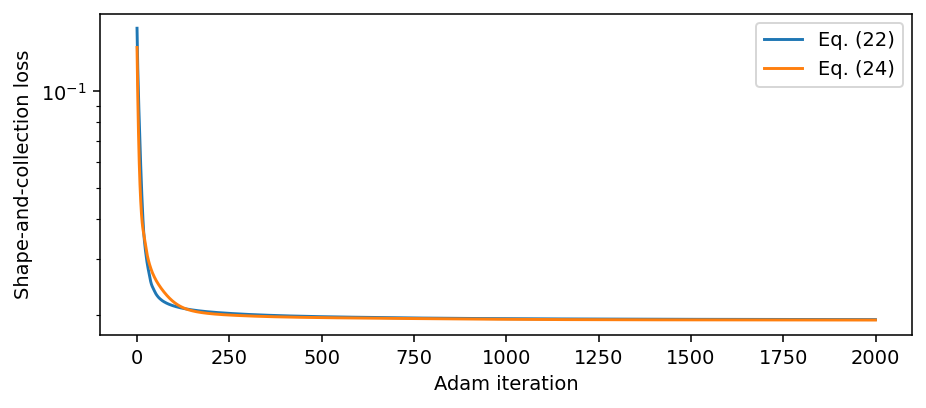

In [14]:
def fig7_optimize(model, start):
    """Run Adam from the supplied phase and keep its lowest-loss pupil."""
    @jax.jit
    def step(state, i):
        phase, first, second, best_phase, best_loss = state
        loss, gradient = jax.value_and_grad(lambda p: fig7.loss(p, model))(phase)
        best_phase = jnp.where(loss < best_loss, phase, best_phase)
        best_loss = jnp.minimum(loss, best_loss)
        first = 0.9*first + 0.1*gradient
        second = 0.999*second + 0.001*gradient**2
        rate = fig7_learning_rate*(0.1 + 0.9*0.5*(1+jnp.cos(jnp.pi*i/fig7_iterations)))
        phase -= rate*(first/(1-0.9**(i+1)))/(jnp.sqrt(second/(1-0.999**(i+1)))+1e-8)
        return (phase, first, second, best_phase, best_loss), loss

    state = (start, jnp.zeros_like(start), jnp.zeros_like(start), start, jnp.asarray(np.inf))
    history = []
    for i in range(fig7_iterations):
        state, loss = step(state, i)
        history.append(float(loss))
        if (i+1) % 200 == 0:
            print(f"{model}: {i+1:4d} steps, loss = {float(loss):.6f}")
    phase, _, _, best_phase, best_loss = state
    final_loss = fig7.loss(phase, model)
    if float(final_loss) < float(best_loss):
        best_phase, best_loss = phase, final_loss
    return dict(phase=np.asarray(best_phase), history=np.asarray(history), loss=float(best_loss),
                E=np.asarray(fig7.irradiance(best_phase, model)), initial_phase=np.asarray(start),
                iterations=fig7_iterations, learning_rate=fig7_learning_rate, signature=fig7.signature)

fig7_designs = {}
for model in ("eq22", "eq24"):
    path = fig7_folder / f"design_{model}.npz"
    data = dict(np.load(path)) if path.exists() and not REOPTIMIZE else None
    matches = (data is not None and int(data["iterations"]) == fig7_iterations
               and float(data["learning_rate"]) == fig7_learning_rate
               and np.array_equal(data["initial_phase"], np.asarray(fig7_start)))
    if not matches:
        data = fig7_optimize(model, fig7_start)
        np.savez_compressed(path, **data)
    fig7_designs[model] = data
    print(f"{model}: best loss = {float(data['loss']):.6f} ({len(data['history'])} Adam steps)")

fig, ax = plt.subplots(figsize=(6.5, 2.8), layout="constrained")
for model, label in (("eq22", "Eq. (22)"), ("eq24", "Eq. (24)")):
    ax.semilogy(fig7_designs[model]["history"], label=label)
ax.set(xlabel="Adam iteration", ylabel="Shape-and-collection loss")
ax.legend()
plt.show()

### Evaluate the three pupils with RS

The focusing comparator adds exactly $-\pi(\xi^2+\eta^2)/(\lambda z_2)$ to the Eq. (22) design. The RS check uses each source sample's spherical incident amplitude and phase, propagates its field with the outgoing RS kernel in angular-spectrum form, and adds intensities. 
Three Gauss nodes per pixel axis resolve the same constant phase pixels, the direct-kernel check below uses four. `pixel_order` controls this integration, and `refinement` widens and refines the spectral patches.

In [15]:
fig7_phases = {
    "eq22": fig7_designs["eq22"]["phase"],
    "focus": fig7_designs["eq22"]["phase"]
             - np.pi*(fig7.xx**2+fig7.yy**2)/(fig7.wavelength*fig7.z2),
    "eq24": fig7_designs["eq24"]["phase"],
}
fig7_rs = {}
fig7_reference = jax.jit(lambda p: fig7.rs_irradiance(p, pixel_order=3, refinement=1))
for name, phase in fig7_phases.items():
    path = fig7_folder / f"rs_{name}.npz"
    data = dict(np.load(path)) if path.exists() and not RECHECK_RS else None
    matches = (data is not None and np.array_equal(data["phase"], phase)
               and int(data["pixel_order"]) == 3 and float(data["refinement"]) == 1)
    if matches:
        fig7_rs[name] = data["E"]
    else:
        fig7_rs[name] = np.asarray(fig7_reference(jnp.asarray(phase)))
        np.savez_compressed(path, E=fig7_rs[name], phase=phase,
                            pixel_order=3, refinement=1, signature=fig7.signature)
    print(f"{name}: RS evaluation complete.")

eq22: RS evaluation complete.
focus: RS evaluation complete.
eq24: RS evaluation complete.


### Calculate the metrics

Each design uses one mean over all nine interiors, $I=\{T>0.95\}$. Shape error includes the tile borders; nonuniformity uses only the interiors. Collection integrates $C=\{T\geq0.5\}$ relative to the incident pupil power. The Eq. (24)–RS comparison uses absolute irradiance.


In [17]:
from IPython.display import display, Markdown

fig7_names = ["eq22", "focus", "eq24"]
fig7_labels = ["Eq. (22)", "Eq. (22) + paraxial focus", "Eq. (24)"]
fig7_metrics = {name: fig7.metrics(fig7_rs[name]) for name in fig7_names}
fig7_table = ["| Design | Shape error [%] | Nonuniformity [%] | Collection [%] |",
              "|:--|--:|--:|--:|"]
for name, label in zip(fig7_names, fig7_labels):
    measured = [100*fig7_metrics[name][key] for key in ("shape_error", "nonuniformity", "collection")]
    entries = " | ".join(f"{value:.2f}" for value in measured)
    fig7_table.append(f"| {label} | {entries} |")
display(Markdown("\n".join(fig7_table)))

fig7_model_error = np.linalg.norm(fig7_designs["eq24"]["E"]-fig7_rs["eq24"])/np.linalg.norm(fig7_rs["eq24"])
print(f"Eq. (24)–RS relative L² error: {100*fig7_model_error:.3f}%.")
for key in ("shape_error", "nonuniformity"):
    ratio = fig7_metrics["focus"][key]/fig7_metrics["eq24"][key]
    print(f"Improvement over added paraxial focus — {key.replace('_', ' ')}: {ratio:.2f}×")
_ = (fig7_folder / "metrics.json").write_text(json.dumps(
    dict(measured=fig7_metrics, eq24_rs_relative_l2=float(fig7_model_error)), indent=2))

| Design | Shape error [%] | Nonuniformity [%] | Collection [%] |
|:--|--:|--:|--:|
| Eq. (22) | 84.53 | 42.73 | 48.82 |
| Eq. (22) + paraxial focus | 22.16 | 20.24 | 65.52 |
| Eq. (24) | 4.90 | 4.50 | 63.74 |

Eq. (24)–RS relative L² error: 0.271%.
Improvement over added paraxial focus — shape error: 4.52×
Improvement over added paraxial focus — nonuniformity: 4.50×


### Fig. 7(b–g)

Note: Each RS image is divided by its own common interior mean, so brightness differences between its nine squares remain visible.

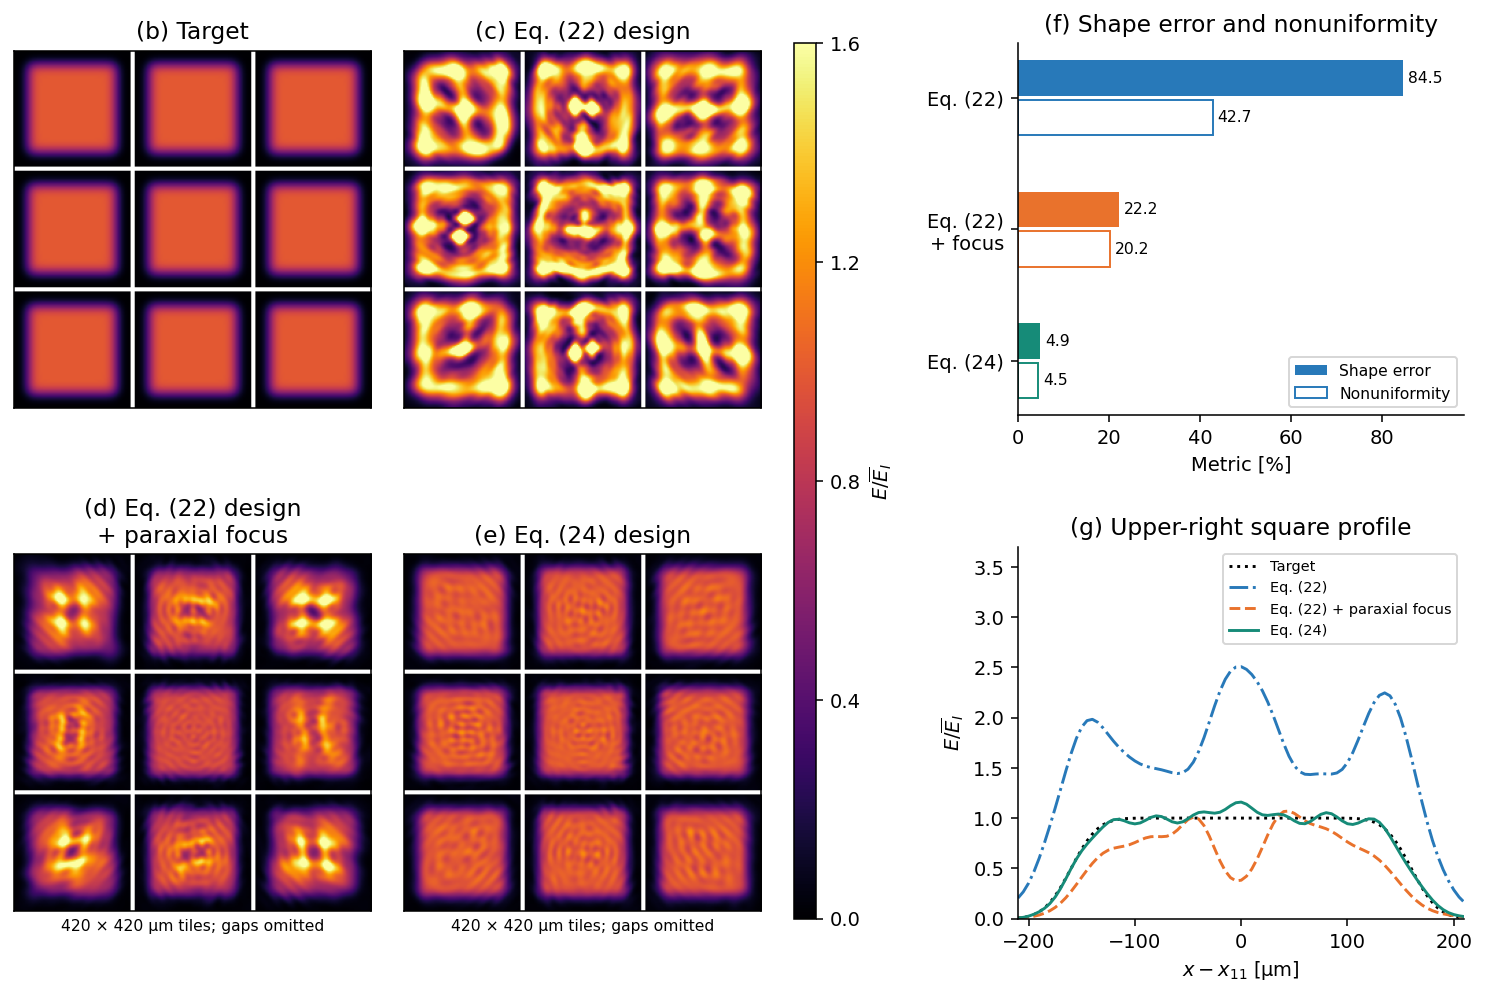

In [18]:
def fig7_mosaic(tiles, gap=3):
    """Arrange the nine tiles from upper left to lower right, leaving small white gaps."""
    n = tiles.shape[-1]
    image = np.full((3*n+2*gap, 3*n+2*gap), np.nan)
    for i, tile in enumerate(tiles):
        row, col = divmod(i, 3)
        # Each tile's first row has the lowest physical y coordinate.
        image[row*(n+gap):row*(n+gap)+n, col*(n+gap):col*(n+gap)+n] = tile[::-1]
    return image

fig7_normalized = {name: E/E[:, fig7.interior].mean() for name, E in fig7_rs.items()}
fig7_colors = ["#2879b9", "#e9722c", "#168b78"]
fig7_figure = plt.figure(figsize=(10.5, 7), layout="constrained")
fig7_grid = fig7_figure.add_gridspec(2, 4, width_ratios=[1, 1, 0.06, 1.25], wspace=0.09)
fig7_images = [np.broadcast_to(np.asarray(fig7.target), (9, len(fig7.local), len(fig7.local))),
               fig7_normalized["eq22"], fig7_normalized["focus"], fig7_normalized["eq24"]]
fig7_titles = ["(b) Target", "(c) Eq. (22) design", "(d) Eq. (22) design\n+ paraxial focus", "(e) Eq. (24) design"]
for position, tiles, title in zip(((0, 0), (0, 1), (1, 0), (1, 1)), fig7_images, fig7_titles):
    ax = fig7_figure.add_subplot(fig7_grid[position])
    im = ax.imshow(fig7_mosaic(tiles), origin="upper", cmap="inferno", vmin=0, vmax=1.6)
    ax.set(title=title, xticks=[], yticks=[])
    if position[0] == 1:
        ax.set_xlabel("420 × 420 µm tiles; gaps omitted", fontsize=8)
fig7_figure.colorbar(im, cax=fig7_figure.add_subplot(fig7_grid[:, 2]),
                    label=r"$E/\overline{E}_I$", ticks=[0, .4, .8, 1.2, 1.6])

ax = fig7_figure.add_subplot(fig7_grid[0, 3])
for i, (name, color) in enumerate(zip(fig7_names, fig7_colors)):
    shape, uniformity = [100*fig7_metrics[name][key] for key in ("shape_error", "nonuniformity")]
    ax.barh(i-.15, shape, height=.27, color=color, label="Shape error" if i == 0 else None)
    ax.barh(i+.15, uniformity, height=.27, facecolor="white", edgecolor=color,
            label="Nonuniformity" if i == 0 else None)
    for y, value in ((i-.15, shape), (i+.15, uniformity)):
        ax.text(value+1, y, f"{value:.1f}", va="center", fontsize=8)
ax.set(title="(f) Shape error and nonuniformity", xlabel="Metric [%]", xlim=(0, 98),
       yticks=range(3), yticklabels=["Eq. (22)", "Eq. (22)\n+ focus", "Eq. (24)"])
ax.invert_yaxis()
ax.legend(loc="lower right", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)

ax = fig7_figure.add_subplot(fig7_grid[1, 3])
middle = len(fig7.local)//2
ax.plot(fig7.local, np.asarray(fig7.target)[middle], "k:", label="Target")
for name, color, style, label in zip(fig7_names, fig7_colors, ["-.", "--", "-"], fig7_labels):
    ax.plot(fig7.local, fig7_normalized[name][2, middle], color=color, linestyle=style, label=label)
ax.set(title="(g) Upper-right square profile", xlabel=r"$x-x_{11}$ [µm]",
       ylabel=r"$E/\overline{E}_I$", xlim=(-210, 210), ylim=(0, 3.7))
ax.legend(loc="upper right", fontsize=7.5)
ax.spines[["top", "right"]].set_visible(False)
fig7_figure.savefig(fig7_folder / "Fig7_b_g.png", dpi=180)
plt.show()